# Datos meteorolóxicos de A Coruña / Alvedro (2021–2025)

Pipeline de datos diarios da estación A Coruña / Alvedro (aeroporto), indicativo **08002**. O ficheiro indica as coordenadas **43,3000° N, -8,3833° O** e altitude **97 m**. A fonte orixinal é Meteostat; o ficheiro foi modificado con fins didácticos.

Neste notebook descárganse, inspecciónanse e límpanse os datos; respóndense as preguntas do apartado 4.4 e créanse catro gráficas en total, incluída a gráfica previa á limpeza.


## 1. Descarga dos datos

Descárgase o CSV con `requests` e gárdase directamente como bytes en `datos/raw/`, sen abrilo nin modificalo. O exemplo usa rutas relativas ao cartafol `notebooks/`, desde onde se debe executar o notebook.


In [1]:
from pathlib import Path
import requests
import pandas as pd
import matplotlib.pyplot as plt

URL = "https://raw.githubusercontent.com/bigdatawirtz/datasets/main/datasets/meteo_alvedro_2021_2025.csv"
resposta = requests.get(URL, timeout=30)
resposta.raise_for_status()
Path("../datos/raw").mkdir(parents=True, exist_ok=True)
Path("../datos/raw/meteo_alvedro_2021_2025.csv").write_bytes(resposta.content)

print(f"Descargados {len(resposta.content):,} bytes")


Descargados 81,825 bytes


## 2. Inspección do ficheiro

Antes de pandas, míranse os bytes e as primeiras/últimas liñas. O ficheiro está codificado en CP1252, ten seis liñas de metadatos, usa `;` como separador e coma decimal. A precipitación tamén contén os códigos `Ip`, `NA` e `-9999`.


In [2]:
datos_bytes = Path("../datos/raw/meteo_alvedro_2021_2025.csv").read_bytes()
texto_raw = datos_bytes.decode("cp1252")
liñas_raw = texto_raw.splitlines()

print("Primeiros bytes:", repr(datos_bytes[:100]))
print("Primeiras liñas:")
print("\n".join(liñas_raw[:8]))
print("\nÚltimas liñas:")
print("\n".join(liñas_raw[-5:]))


Primeiros bytes: b'Servizo de exportaci\xf3n de datos meteorol\xf3xicos\nEstaci\xf3n: A Coru\xf1a / Alvedro (aeroporto) \xb7 Indicativo'
Primeiras liñas:
Servizo de exportación de datos meteorolóxicos
Estación: A Coruña / Alvedro (aeroporto) · Indicativo: 08002
Latitude: 43,3000 · Lonxitude: -8,3833 · Altitude: 97 m
Período: 01/01/2021 - 31/12/2025
Fonte orixinal: Meteostat (meteostat.net). Ficheiro modificado con fins didácticos.

Data;Temp. media (ºC);Temp. mínima (ºC);Temp. máxima (ºC);Humidade relativa (%);Precipitación (mm);Vento medio (km/h);Presión (hPa)
2021-01-01;5,9;3,3;9,1;87;12,2;11,0;1.015,7

Últimas liñas:
2025-06-10;20,8;15,6;27,6;80;Ip;6,2;1.015,7
2021-04-16;10,0;3,6;17,2;56;0,0;11,7;1.020,1
2022-05-21;19,9;10,9;24,7;81;2,9;5,8;1.015,6
2025-10-12;17,6;9,9;24,9;74;0,0;5,8;1.018,8
17/08/2023;20,1;14,2;26,7;77;0,5;9,3;1.014,7


In [3]:
def parsear_data_orixinal(valores):
    texto = valores.astype("string").str.strip()
    datas = pd.to_datetime(texto, format="%Y-%m-%d", errors="coerce")
    formato_dia_mes = datas.isna()
    datas.loc[formato_dia_mes] = pd.to_datetime(
        texto.loc[formato_dia_mes], format="%d/%m/%Y", errors="coerce"
    )
    return datas


def parsear_numero(valor):
    texto = str(valor).strip()
    if texto.upper() in {"", "NA", "-9999"}:
        return float("nan")
    if texto.casefold() == "ip":
        return 0.0
    if "," in texto and "." in texto:
        texto = texto.replace(".", "").replace(",", ".")
    else:
        texto = texto.replace(",", ".")
    return float(texto)


try:
    pd.read_csv(Path("../datos/raw/meteo_alvedro_2021_2025.csv"))
except UnicodeDecodeError as erro:
    print(type(erro).__name__, "→", erro)

df_novo = pd.read_csv(
    Path("../datos/raw/meteo_alvedro_2021_2025.csv"),
    sep=";",
    skiprows=6,
    encoding="cp1252",
)
df_novo.info()
print("\nValores de precipitación que aparecen no ficheiro:")
print(df_novo["Precipitación (mm)"].value_counts().head(8))


UnicodeDecodeError → 'utf-8' codec can't decode byte 0xf3 in position 20: invalid continuation byte
<class 'pandas.DataFrame'>
RangeIndex: 1812 entries, 0 to 1811
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Data                   1812 non-null   str  
 1   Temp. media (ºC)       1803 non-null   str  
 2   Temp. mínima (ºC)      1806 non-null   str  
 3   Temp. máxima (ºC)      1803 non-null   str  
 4   Humidade relativa (%)  1812 non-null   int64
 5   Precipitación (mm)     1804 non-null   str  
 6   Vento medio (km/h)     1812 non-null   str  
 7   Presión (hPa)          1811 non-null   str  
dtypes: int64(1), str(7)
memory usage: 113.4 KB

Valores de precipitación que aparecen no ficheiro:
Precipitación (mm)
0,0    809
Ip     121
0,2     49
0,3     34
0,4     29
0,5     28
0,7     23
0,9     21
Name: count, dtype: int64


## 3. Gráfica previa á limpeza

A gráfica permite ver a temperatura máxima orixinal e localizar valores que destacan antes de corrixilos.


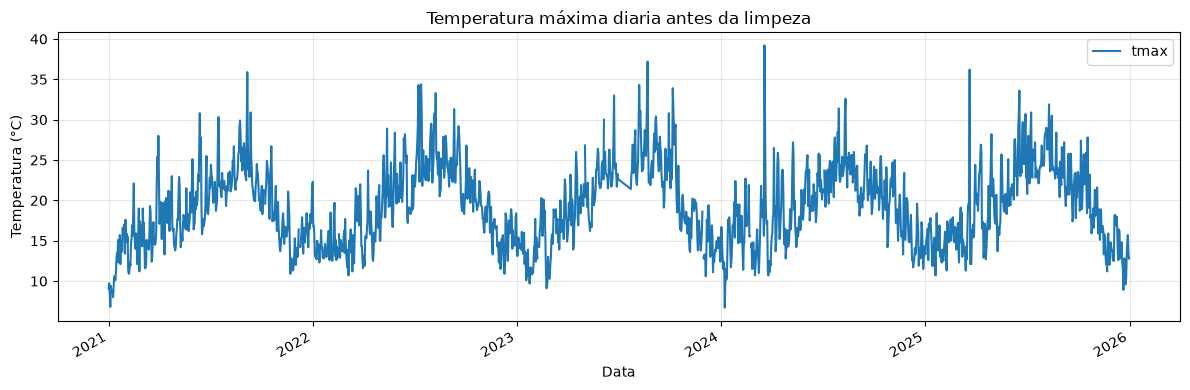

In [4]:
datas_grafica = parsear_data_orixinal(df_novo["Data"])
tmax_raw = df_novo["Temp. máxima (ºC)"].map(parsear_numero)

df_grafica = pd.DataFrame({"data": datas_grafica, "tmax": tmax_raw}).sort_values("data")
df_grafica.plot(x="data", y="tmax", figsize=(12, 4), title="Temperatura máxima diaria antes da limpeza")
plt.xlabel("Data")
plt.ylabel("Temperatura (°C)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 4. Limpeza dos datos

As decisións principais son: converter os códigos de ausencia en valores nulos; interpretar `Ip` como 0 mm; ordenar as datas; eliminar duplicados conservando a primeira fila; completar o calendario diario; e deixar como nulos os valores imposibles ou sospeitosos. Non se interpolan os datos ausentes: así non se inventan observacións, especialmente no oco longo de xullo de 2023.


In [5]:
nomes_columnas = {
    "Data": "data",
    "Temp. media (ºC)": "tmed",
    "Temp. mínima (ºC)": "tmin",
    "Temp. máxima (ºC)": "tmax",
    "Humidade relativa (%)": "hum",
    "Precipitación (mm)": "prec",
    "Vento medio (km/h)": "vento",
    "Presión (hPa)": "pres",
}

meteo = df_novo.rename(columns=nomes_columnas).copy()
meteo["data"] = parsear_data_orixinal(meteo["data"])

for columna in ["tmed", "tmin", "tmax", "hum", "prec", "vento", "pres"]:
    meteo[columna] = meteo[columna].map(parsear_numero)

print("Datas que non se puideron ler:", meteo["data"].isna().sum())
print("Valores ausentes por variable antes da limpeza:")
print(meteo.isna().sum().to_string())

print("\nFilas con datas duplicadas:", meteo["data"].duplicated().sum())
meteo = meteo.sort_values("data").drop_duplicates(subset="data", keep="first")

calendario = pd.date_range("2021-01-01", "2025-12-31", freq="D")
dias_faltantes = calendario.difference(meteo["data"])
print("Días que faltan:", len(dias_faltantes))
print(dias_faltantes.to_list())
meteo = meteo.set_index("data").reindex(calendario)
meteo.index.name = "data"

mes = meteo.index.month
maximas_anomalas = (meteo["tmax"] > 35) & ~mes.isin([6, 7, 8])
minimas_anomalas = (meteo["tmin"] < 0) & mes.isin([6, 7, 8, 9])
print("Máximas superiores a 35 °C fóra do verán:", maximas_anomalas.sum())
print("Mínimas negativas entre xuño e setembro:", minimas_anomalas.sum())
meteo.loc[maximas_anomalas, "tmax"] = float("nan")
meteo.loc[minimas_anomalas, "tmin"] = float("nan")

inconsistencias = meteo["tmin"] > meteo["tmax"]
print("Días con mínima superior á máxima:", inconsistencias.sum())
meteo.loc[inconsistencias, ["tmin", "tmax"]] = float("nan")
media_fóra_rango = (meteo["tmed"] < meteo["tmin"]) | (meteo["tmed"] > meteo["tmax"])
print("Medias fóra do intervalo entre mínima e máxima:", media_fóra_rango.sum())
meteo.loc[media_fóra_rango, "tmed"] = float("nan")

meteo = meteo.reset_index()
meteo["ano"] = meteo["data"].dt.year
meteo["mes"] = meteo["data"].dt.month
print("\nValores ausentes despois da limpeza:")
print(meteo.isna().sum().to_string())


Datas que non se puideron ler: 0
Valores ausentes por variable antes da limpeza:
data      0
tmed     12
tmin     12
tmax     12
hum       0
prec     10
vento     0
pres      1

Filas con datas duplicadas: 13
Días que faltan: 27
[Timestamp('2021-02-17 00:00:00'), Timestamp('2021-05-25 00:00:00'), Timestamp('2021-11-19 00:00:00'), Timestamp('2022-10-21 00:00:00'), Timestamp('2023-04-23 00:00:00'), Timestamp('2023-07-03 00:00:00'), Timestamp('2023-07-04 00:00:00'), Timestamp('2023-07-05 00:00:00'), Timestamp('2023-07-06 00:00:00'), Timestamp('2023-07-07 00:00:00'), Timestamp('2023-07-08 00:00:00'), Timestamp('2023-07-09 00:00:00'), Timestamp('2023-07-10 00:00:00'), Timestamp('2023-07-11 00:00:00'), Timestamp('2023-07-12 00:00:00'), Timestamp('2023-07-13 00:00:00'), Timestamp('2023-07-14 00:00:00'), Timestamp('2023-07-15 00:00:00'), Timestamp('2023-07-16 00:00:00'), Timestamp('2023-07-17 00:00:00'), Timestamp('2023-07-18 00:00:00'), Timestamp('2023-07-19 00:00:00'), Timestamp('2023-07-20 

### Gardado dos datos limpos

Gárdase o resultado en `datos/clean/` con codificación UTF-8. Os valores ausentes mantéñense como ausentes e as análises teñen en conta esa decisión.


In [6]:
Path("../datos/clean").mkdir(parents=True, exist_ok=True)
meteo.to_csv(
    Path("../datos/clean/meteo_alvedro_2021_2025_limpo.csv"),
    index=False,
    encoding="utf-8",
    date_format="%Y-%m-%d",
)
print("Ficheiro limpo gardado en datos/clean/")


Ficheiro limpo gardado en datos/clean/


## 5. Análise

Nas preguntas de precipitación non se contan os meses incompletos, para non tratar días sen dato como días secos. Considérase día chuvioso o que ten **polo menos 1 mm**.


### 5.1 Temperatura media anual

Calcúlase a media da temperatura media diaria de cada ano. A comparación é descritiva: cinco anos non abondan para afirmar unha tendencia climática a longo prazo.


In [7]:
tmed_anual = meteo.groupby("ano")["tmed"].mean()
print("Temperatura media anual (°C):")
print(tmed_anual.round(2))
diferencia = tmed_anual.iloc[-1] - tmed_anual.iloc[0]
print(
    f"Interpretación: entre 2021 e 2025 a media cambiou {diferencia:+.2f} °C, "
    "con variacións dun ano a outro."
)


Temperatura media anual (°C):
ano
2021    14.11
2022    14.98
2023    14.91
2024    14.45
2025    14.45
Name: tmed, dtype: float64
Interpretación: entre 2021 e 2025 a media cambiou +0.33 °C, con variacións dun ano a outro.


### 5.2 Mes máis e menos chuvioso

Calcúlase primeiro a precipitación total de cada mes; para a media por mes do ano só se usan meses con datos completos.


In [8]:
prec_mensual = meteo.groupby(["ano", "mes"]).agg(
    total_prec=("prec", lambda valores: valores.sum(min_count=1)),
    dias_con_dato=("prec", "count"),
    dias_mes=("prec", "size"),
)
meses_completos = prec_mensual["dias_con_dato"] == prec_mensual["dias_mes"]
totais_completos = prec_mensual.loc[meses_completos, "total_prec"]
prec_media_mes = totais_completos.groupby("mes").mean()
meses_galegos = {
    1: "Xaneiro", 2: "Febreiro", 3: "Marzo", 4: "Abril",
    5: "Maio", 6: "Xuño", 7: "Xullo", 8: "Agosto",
    9: "Setembro", 10: "Outubro", 11: "Novembro", 12: "Decembro",
}
mes_mais_chuvioso = prec_media_mes.idxmax()
mes_mais_seco = prec_media_mes.idxmin()
print("Meses completos para a comparación:", meses_completos.sum(), "de 60")
print("Precipitación media por mes (mm):")
print(prec_media_mes.rename(index=meses_galegos).round(1))
print(
    f"Interpretación: {meses_galegos[mes_mais_chuvioso]} é o máis chuvioso e "
    f"{meses_galegos[mes_mais_seco]} o máis seco de media."
)


Meses completos para a comparación: 44 de 60
Precipitación media por mes (mm):
mes
Xaneiro     125.8
Febreiro     78.8
Marzo        69.3
Abril        92.2
Maio         62.4
Xuño         37.0
Xullo        23.5
Agosto       15.4
Setembro     75.0
Outubro     120.7
Novembro    164.6
Decembro    160.0
Name: total_prec, dtype: float64
Interpretación: Novembro é o máis chuvioso e Agosto o máis seco de media.


### 5.3 Días chuviosos por mes

Cóntanse os días con precipitación ≥ 1 mm e calcúlase a media para cada mes do calendario, contando só os meses completos.


In [9]:
meteo["dia_chuvioso"] = meteo["prec"] >= 1
chuvia_mes_ano = meteo.groupby(["ano", "mes"])["dia_chuvioso"].sum()
dias_chuviosos = chuvia_mes_ano.loc[meses_completos].groupby("mes").mean()
print("Media de días chuviosos por mes (≥ 1 mm):")
print(dias_chuviosos.rename(index=meses_galegos).round(1))
mes_máis_chuvioso_en_dias = dias_chuviosos.idxmax()
print(
    f"Interpretación: {meses_galegos[mes_máis_chuvioso_en_dias]} ten a maior media "
    "de días chuviosos nos meses completos dispoñibles."
)


Media de días chuviosos por mes (≥ 1 mm):
mes
Xaneiro     14.0
Febreiro     9.5
Marzo       10.2
Abril       10.8
Maio         8.5
Xuño         7.0
Xullo        7.5
Agosto       4.7
Setembro    11.8
Outubro     13.0
Novembro    17.2
Decembro    15.8
Name: dia_chuvioso, dtype: float64
Interpretación: Novembro ten a maior media de días chuviosos nos meses completos dispoñibles.


### 5.4 Días máis quente e máis frío de cada ano

Atópanse a data da máxima diaria máis alta e a mínima diaria máis baixa de cada ano.


In [10]:
idx_quente = meteo.groupby("ano")["tmax"].idxmax()
idx_frio = meteo.groupby("ano")["tmin"].idxmin()
dias_quentes = meteo.loc[idx_quente, ["ano", "data", "tmax"]].set_index("ano")
dias_frios = meteo.loc[idx_frio, ["ano", "data", "tmin"]].set_index("ano")
print("Día máis quente de cada ano:")
print(dias_quentes.to_string(index=False))
print("\nDía máis frío de cada ano:")
print(dias_frios.to_string(index=False))
print("Interpretación: os días extremos varían dun ano a outro.")


Día máis quente de cada ano:
      data  tmax
2021-09-12  30.9
2022-07-14  34.4
2023-08-23  37.2
2024-08-11  32.6
2025-06-18  33.6

Día máis frío de cada ano:
      data  tmin
2021-01-08  -3.2
2022-01-23  -1.8
2023-01-31  -2.3
2024-01-12  -2.0
2025-12-27  -1.6
Interpretación: os días extremos varían dun ano a outro.


## 6. Gráficas dos datos limpos

Gráficas básicas de evolución da temperatura, precipitación mensual e comparación da temperatura media mensual de 2025 coa media de 2021–2024.


### 6.1 Temperatura media diaria e media móbil

A media móbil de 30 días suaviza as variacións diarias e facilita ver a evolución xeral.


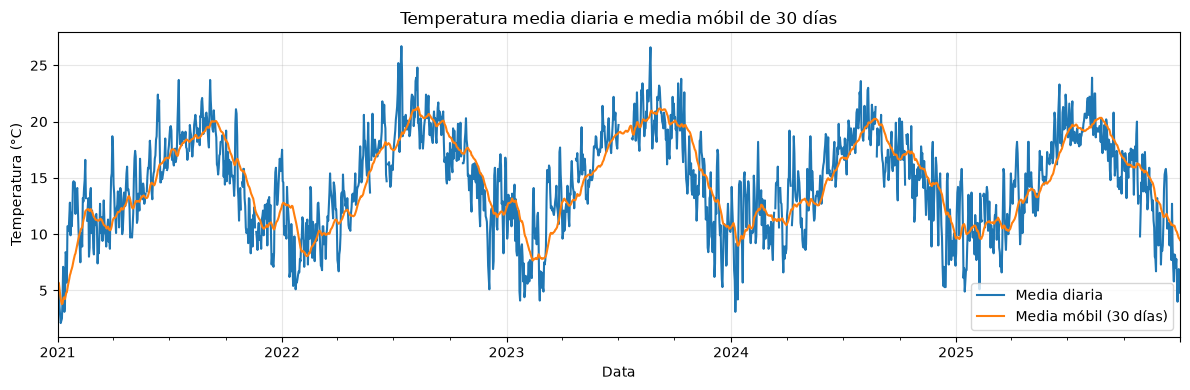

In [11]:
meteo["tmed_media_mobil"] = meteo["tmed"].rolling(30, min_periods=1).mean()
meteo.plot(x="data", y=["tmed", "tmed_media_mobil"], figsize=(12, 4))
plt.title("Temperatura media diaria e media móbil de 30 días")
plt.xlabel("Data")
plt.ylabel("Temperatura (°C)")
plt.legend(["Media diaria", "Media móbil (30 días)"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 6.2 Precipitación mensual

Amósanse os totais mensuais só para os meses con todos os días observados.


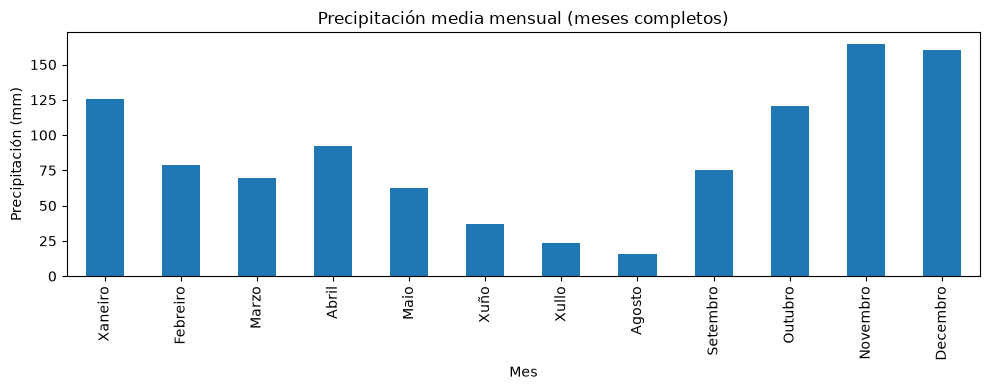

In [12]:
prec_media_mes.rename(index=meses_galegos).plot(kind="bar", figsize=(10, 4), legend=False)
plt.title("Precipitación media mensual (meses completos)")
plt.xlabel("Mes")
plt.ylabel("Precipitación (mm)")
plt.tight_layout()
plt.show()


### 6.3 Comparación de 2025 coa media de 2021–2024

Compárase a temperatura media de cada mes de 2025 coa media dese mes nos catro anos anteriores.


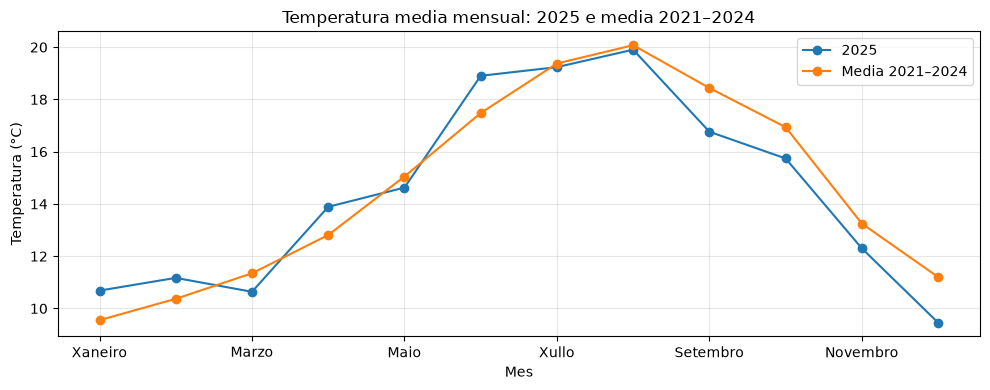

In [13]:
temperatura_mensual = meteo.groupby(["ano", "mes"])["tmed"].mean().unstack("ano")
media_2021_2024 = temperatura_mensual[[2021, 2022, 2023, 2024]].mean(axis=1)
comparacion = pd.DataFrame({
    "2025": temperatura_mensual[2025],
    "Media 2021–2024": media_2021_2024,
})
comparacion.index = comparacion.index.map(meses_galegos)
comparacion.plot(marker="o", figsize=(10, 4))
plt.title("Temperatura media mensual: 2025 e media 2021–2024")
plt.xlabel("Mes")
plt.ylabel("Temperatura (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
